# Inducción de árboles de decisión (TDIDT)

Implementación desde cero de los algoritmos ID3 y C4.5 sobre el conjunto de datos
`data/dataset_tenis.csv`. El cuaderno cubre las medidas de información que gobiernan la
selección de atributos (entropía, ganancia de información y gain ratio), la
construcción recursiva del árbol, la extracción automática de reglas y la evaluación
del clasificador.

Todo el código es propio: no se usa ninguna librería de aprendizaje automático, sólo
`pandas` para la manipulación de datos y `matplotlib` para los gráficos. Requisitos:
Python 3.10 o superior, pandas y matplotlib.

## 1. Alcance y aplicabilidad

TDIDT (*Top-Down Induction of Decision Trees*) engloba los algoritmos que inducen un
árbol de decisión de forma greedy y recursiva a partir de datos etiquetados. La familia
incluye a ID3 (Quinlan, 1986), C4.5 (Quinlan, 1993) y CART (Breiman et al., 1984); este
cuaderno se concentra en los dos primeros.

### Cuándo conviene usar TDIDT

- El problema es de clasificación supervisada: la variable objetivo es categórica y
  existe un conjunto de instancias etiquetadas.
- Se requiere interpretabilidad: el modelo tiene que poder revisarse, auditarse o
  explicarse ante alguien sin fondo estadístico.
- Se necesitan reglas de decisión explícitas, ejecutables fuera del modelo (controles
  de negocio, validaciones de proceso, diagnósticos).
- Los atributos son categóricos (ID3) o mixtos (C4.5 discretiza los continuos).
- Se busca una línea base rápida de entrenar antes de probar modelos más pesados
  (ensembles, redes neuronales).

Casos donde TDIDT en su forma simple no es la herramienta adecuada:

- Ruido alto o valores faltentes: sin poda, ID3 tiende a memorizar y el árbol crece
  hasta clasificar exactamente el conjunto de entrenamiento.
- Pocas instancias y muchos atributos: la selección greedy elige atributos que separan
  el entrenamiento sin poder de generalización.
- Variable objetivo continua: eso corresponde a árboles de regresión, otra familia.

### Qué información entrega el modelo

Un árbol inducido no es sólo un clasificador. Entrega la estructura de decisión
(particiones *axis-aligned* sobre el espacio de atributos), un orden de importancia de
los atributos (los que aparecen cerca de la raíz son los que más reducen la
incertidumbre) y un conjunto de reglas equivalente, que se extrae recorriendo cada
camino raíz-hoja. Esa transparencia es la razón principal para elegir un árbol frente a
un modelo de caja negra cuando el requisito no es sólo exactitud.

## 2. Marco teórico

### Entropía

Sea $S$ un conjunto de $n$ ejemplos clasificados en $c$ clases, con $p_i$ la proporción
de ejemplos de la clase $i$:

$$H(S) = -\sum_{i=1}^{c} p_i \log_2 p_i$$

Por convención, $0 \log_2 0 = 0$. $H(S)$ alcanza su máximo $\log_2 c$ cuando las
clases están uniformemente distribuidas. Para un problema binario,
$H(S) \in [0, 1]$; el valor cero indica que el conjunto es puro.

### Ganancia de información

La ganancia de un atributo $A$ mide la reducción esperada de entropía al usarlo como
criterio de partición:

$$\mathrm{Ganancia}(S, A) = H(S) - \sum_{v \in \mathrm{Valores}(A)} \frac{|S_v|}{|S|} H(S_v)$$

donde $S_v$ es el subconjunto de ejemplos con $A = v$. El segundo término es la
entropía residual ponderada: cuánta incertidumbre queda después de la división. ID3
selecciona en cada nodo el atributo con mayor ganancia.

### Split info y gain ratio

La ganancia absoluta favorece a los atributos con muchos valores distintos: un atributo
casi único produce subconjuntos pequeños y puros, y su ganancia crece con la
cardinalidad. C4.5 normaliza la ganancia por la entropía de la propia partición, el
llamado *split info*:

$$\mathrm{SplitInfo}(S, A) = -\sum_{v \in \mathrm{Valores}(A)} \frac{|S_v|}{|S|} \log_2 \frac{|S_v|}{|S|}$$

$$\mathrm{GainRatio}(S, A) = \frac{\mathrm{Ganancia}(S, A)}{\mathrm{SplitInfo}(S, A)}$$

El split info mide cuánta información aporta el nombre del valor que le toca a un
ejemplo; a más equilibradas las ramas, mayor es. C4.5 selecciona el atributo con mayor
gain ratio, con una condición previa: sólo compiten los atributos cuya ganancia supera
la ganancia promedio de los disponibles. Ese filtro evita que un atributo de ganancia
baja pero ramas muy equilibradas gane por normalización.

### Supuestos

1. La variable objetivo es categórica y las instancias están etiquetadas
   (aprendizaje supervisado).
2. Los atributos son categóricos; ID3 no admite atributos continuos y C4.5 los trata
   discretizándolos por umbrales.
3. Las instancias son independientes entre sí.
4. La estrategia de selección es greedy y sin backtracking: el árbol resultante no está
   garantizado como óptimo global.
5. La implementación de este cuaderno no contempla valores faltantes.
6. Los logaritmos son en base 2, de modo que las medidas quedan expresadas en bits.

### Costo computacional

La inducción cuesta $O(n \cdot m \cdot v)$ en el caso típico: en cada nodo se evalúan los
$m$ atributos disponibles sobre las $n$ instancias del nodo, y cada atributo tiene en
promedio $v$ valores. El costo de predicción queda acotado por la profundidad del árbol.

In [1]:
import math
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

In [2]:
RUTA = "data/dataset_tenis.csv"

df = pd.read_csv(RUTA)
ATRIBUTOS = [c for c in df.columns if c != "Juego"]
OBJETIVO = "Juego"

print(f"Instancias: {df.shape[0]}")
print(f"Atributos : {ATRIBUTOS}")
print(f"Clases    : {sorted(df[OBJETIVO].unique())}")
df.head()

Instancias: 14
Atributos : ['Estado', 'Humedad', 'Viento']
Clases    : ['No', 'Si']


,Estado,Humedad,Viento,Juego
0,Soleado,Alta,Leve,No
1,Soleado,Alta,Fuerte,No
2,Nublado,Alta,Leve,Si
3,Lluvia,Alta,Leve,Si
4,Lluvia,Normal,Leve,Si


## 3. Conjunto de datos

El dataset registra decisiones de juego de tenis bajo distintas condiciones climáticas.
Cada fila es una observación y la columna `Juego` es la clase a predecir.

| Atributo  | Valores                  | Rol         |
|-----------|--------------------------|-------------|
| Estado    | Soleado, Nublado, Lluvia | predictivo  |
| Humedad   | Alta, Normal             | predictivo  |
| Viento    | Leve, Fuerte             | predictivo  |
| Juego     | Si, No                   | objetivo    |

Son 14 instancias, muy pocas para un problema real: el conjunto se usa aquí para
verificar los cálculos a mano, no para entrenar un modelo productivo. Con tamaños así,
toda medida de exactitud sobre el entrenamiento está inflada (sección 8).

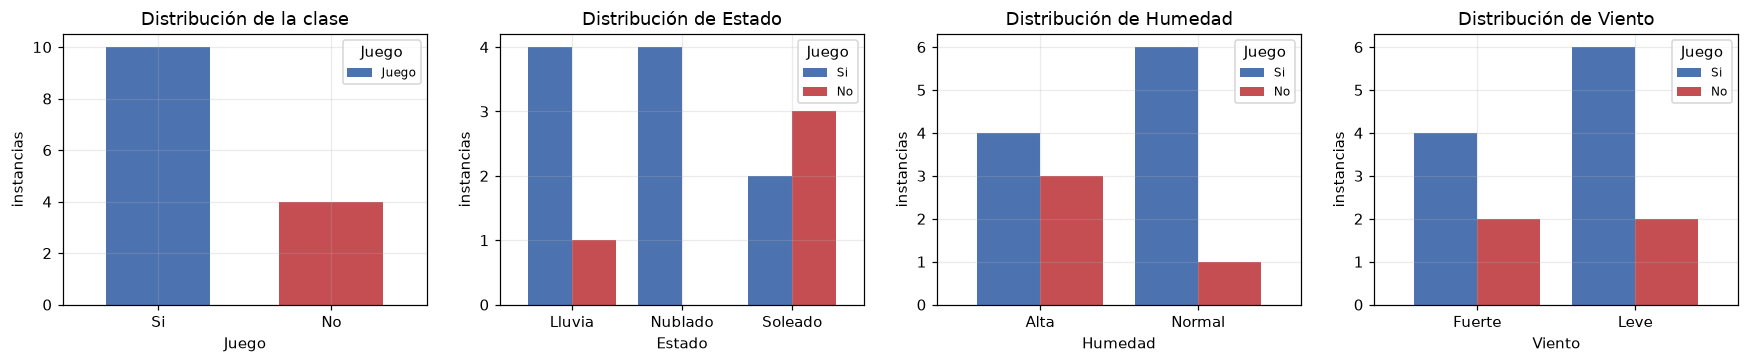

In [3]:
PALETA = {"Si": "#4c72b0", "No": "#c44e52"}

fig, ejes = plt.subplots(1, 4, figsize=(16, 3.4))

conteo = df[OBJETIVO].value_counts().reindex(["Si", "No"]).rename("Juego")
conteo.plot.bar(ax=ejes[0], color=[PALETA[c] for c in conteo.index], rot=0, width=0.6)
ejes[0].set_title("Distribución de la clase")
ejes[0].set_ylabel("instancias")
ejes[0].legend(title="Juego", fontsize=8)

for eje, col in zip(ejes[1:], ATRIBUTOS):
    tabla = pd.crosstab(df[col], df[OBJETIVO]).reindex(columns=["Si", "No"], fill_value=0)
    tabla.plot.bar(ax=eje, color=[PALETA["Si"], PALETA["No"]], rot=0, width=0.8)
    eje.set_title(f"Distribución de {col}")
    eje.set_ylabel("instancias")
    eje.legend(title="Juego", fontsize=8)

fig.tight_layout()
plt.show()

## 4. Medidas de información

Las funciones siguientes implementan directamente las fórmulas de la sección 2. La
entropía trabaja sobre una `Series` de pandas para que sea reutilizable tanto en la
evaluación de atributos como en la construcción recursiva del árbol.

In [4]:
def entropia(series):
    """H(S) = -sum(p_i * log2(p_i)) sobre la distribución de clases."""
    n = len(series)
    if n == 0:
        return 0.0
    return -sum((c / n) * math.log2(c / n) for c in Counter(series).values())


def ganancia(df, atributo, objetivo):
    """H(S) menos la entropía residual ponderada por las ramas del atributo."""
    h_total = entropia(df[objetivo])
    n = len(df)
    residual = 0.0
    for _, subdf in df.groupby(atributo):
        residual += (len(subdf) / n) * entropia(subdf[objetivo])
    return h_total - residual


def split_info(df, atributo):
    """Entropía de la partición: -sum(p_v * log2(p_v)) sobre los valores."""
    n = len(df)
    return -sum((len(subdf) / n) * math.log2(len(subdf) / n)
                for _, subdf in df.groupby(atributo))


def gain_ratio(df, atributo, objetivo):
    """Ganancia normalizada por el split info del atributo."""
    s = split_info(df, atributo)
    return ganancia(df, atributo, objetivo) / s if s > 0 else 0.0

In [5]:
def resumen_medidas(df, atributos, objetivo):
    """Tabla comparativa de ganancia y gain ratio para todos los atributos."""
    return pd.DataFrame({
        "ganancia": [ganancia(df, a, objetivo) for a in atributos],
        "split_info": [split_info(df, a) for a in atributos],
        "gain_ratio": [gain_ratio(df, a, objetivo) for a in atributos],
    }, index=atributos)


h_total = entropia(df[OBJETIVO])
print(f"H(S) = {h_total:.6f} bits")
print(f"Clases: {dict(Counter(df[OBJETIVO]))}\n")
resumen_medidas(df, ATRIBUTOS, OBJETIVO)

H(S) = 0.863121 bits
Clases: {'No': 4, 'Si': 10}



,ganancia,split_info,gain_ratio
Estado,0.258521,1.577406,0.163890
Humedad,0.074670,1.000000,0.074670
Viento,0.005978,0.985228,0.006067


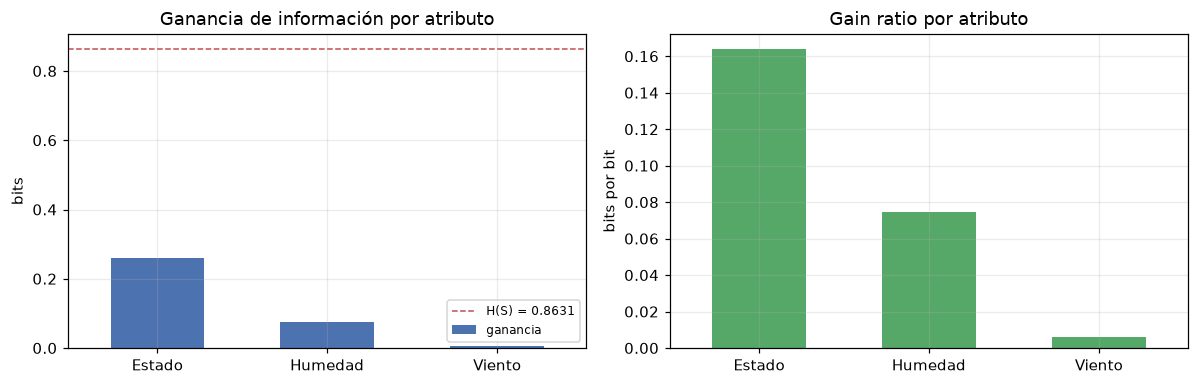

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))

tabla_ganancia = resumen_medidas(df, ATRIBUTOS, OBJETIVO)["ganancia"]
tabla_ganancia.plot.bar(ax=ejes[0], color="#4c72b0", rot=0, width=0.55)
ejes[0].axhline(h_total, color="#c44e52", ls="--", lw=1, label=f"H(S) = {h_total:.4f}")
ejes[0].set_title("Ganancia de información por atributo")
ejes[0].set_ylabel("bits")
ejes[0].legend(fontsize=8)

resumen_medidas(df, ATRIBUTOS, OBJETIVO)["gain_ratio"].plot.bar(
    ax=ejes[1], color="#55a868", rot=0, width=0.55)
ejes[1].set_title("Gain ratio por atributo")
ejes[1].set_ylabel("bits por bit")

fig.tight_layout()
plt.show()

`Estado` es el mejor atributo en ambas medidas: reduce la entropía total en 0.2585 bits y
su gain ratio (0.1639) es más del doble que el del segundo atributo. La razón es la rama
`Nublado`, que resulta pura: 4 de 4 instancias de esa rama son "Si".

La diferencia entre los dos rankings es chica en este dataset porque los tres atributos
tienen pocos valores (2 o 3) y ramas equilibradas; el sesgo de la ganancia hacia
atributos de alta cardinalidad sólo se manifiesta con atributos de muchos valores, que
es justamente lo que el gain ratio corrige. Con estos números, ID3 y C4.5 eligen el mismo
nodo raíz.

## 5. Construcción del árbol con ID3

ID3 aplica tres casos en cada llamada recursiva:

1. Todos los ejemplos del nodo pertenecen a la misma clase: se devuelve una hoja con esa
   clase.
2. No quedan atributos disponibles: se devuelve una hoja con la clase mayoritaria del
   nodo.
3. En otro caso: se selecciona el atributo de mayor ganancia, se particiona el conjunto
   por cada valor observado y se repite el proceso en cada subconjunto.

Pseudocódigo:

```text
ID3(S, A):
    si todos los ejemplos de S tienen la misma clase c:
        devolver hoja(c)
    si A esta vacio:
        devolver hoja(clase mayoritaria de S)
    B <- argmax { Ganancia(S, a) : a en A }
    para cada valor v de B presente en S:
        S_v <- { e en S : e.B = v }
        hijo_v <- ID3(S_v, A - {B})
    devolver nodo(B, {v: hijo_v})
```

La selección del mejor atributo se parametriza con una función `selector`, de modo que
la misma construcción recursiva sirva para ID3 y para C4.5 cambiando sólo ese criterio.

In [7]:
class NodoArbol:
    """Nodo del árbol: interno (test sobre un atributo) u hoja (clase predicha)."""

    def __init__(self, atributo=None, hijos=None, conteo=None):
        self.atributo = atributo
        self.hijos = hijos or {}
        self.conteo = conteo or Counter()   # distribución de clases de entrenamiento
        self.valor = None                   # clase predicha, sólo en hojas

    def es_hoja(self):
        return self.atributo is None

    def predecir(self, fila):
        if self.es_hoja():
            return self.valor
        hijo = self.hijos.get(fila[self.atributo])
        if hijo is None:
            # valor no observado en entrenamiento: se responde con la
            # clase mayoritaria del nodo (fallback documentado)
            return self.conteo.most_common(1)[0][0]
        return hijo.predecir(fila)


def selector_id3(df, atributos, objetivo):
    """ID3: mayor ganancia de información."""
    return max(atributos, key=lambda a: ganancia(df, a, objetivo))


def construir_arbol(df, atributos, objetivo, selector):
    """Construcción recursiva; el selector define el criterio de mejor atributo."""
    conteo = Counter(df[objetivo])
    nodo = NodoArbol(conteo=conteo)

    if len(conteo) == 1:                    # caso 1: nodo puro
        nodo.valor = conteo.most_common(1)[0][0]
        return nodo
    if not atributos:                       # caso 2: sin atributos -> mayoritaria
        nodo.valor = conteo.most_common(1)[0][0]
        return nodo

    elegido = selector(df, atributos, objetivo)
    nodo.atributo = elegido
    for valor, subdf in df.groupby(elegido, sort=True):
        nodo.hijos[valor] = construir_arbol(
            subdf, [a for a in atributos if a != elegido], objetivo, selector)
    return nodo

In [8]:
def describir_arbol(nodo, nivel=0):
    """Impresión textual del árbol con la distribución de clases por nodo."""
    sangria = "  " * nivel
    if nodo.es_hoja():
        print(f"{sangria}-> {OBJETIVO} = {nodo.valor}  {dict(nodo.conteo)}")
        return
    print(f"{sangria}[{nodo.atributo}]  {dict(nodo.conteo)}")
    for valor, hijo in nodo.hijos.items():
        print(f"{sangria}  ({valor})")
        describir_arbol(hijo, nivel + 2)


arbol_id3 = construir_arbol(df, ATRIBUTOS, OBJETIVO, selector_id3)
describir_arbol(arbol_id3)

[Estado]  {'No': 4, 'Si': 10}
  (Lluvia)
    [Viento]  {'Si': 4, 'No': 1}
      (Fuerte)
        [Humedad]  {'No': 1, 'Si': 1}
          (Alta)
            -> Juego = Si  {'Si': 1}
          (Normal)
            -> Juego = No  {'No': 1}
      (Leve)
        -> Juego = Si  {'Si': 3}
  (Nublado)
    -> Juego = Si  {'Si': 4}
  (Soleado)
    [Humedad]  {'No': 3, 'Si': 2}
      (Alta)
        -> Juego = No  {'No': 3}
      (Normal)
        -> Juego = Si  {'Si': 2}


## 6. Visualización y reglas

La figura siguiente dibuja el árbol con el layout clásico: nodos internos con el
atributo de test, hojas con la clase predicha y aristas etiquetadas con el valor del
atributo. Bajo cada nodo interno se muestra la distribución de clases de las instancias
que llegaron a ese punto durante el entrenamiento.

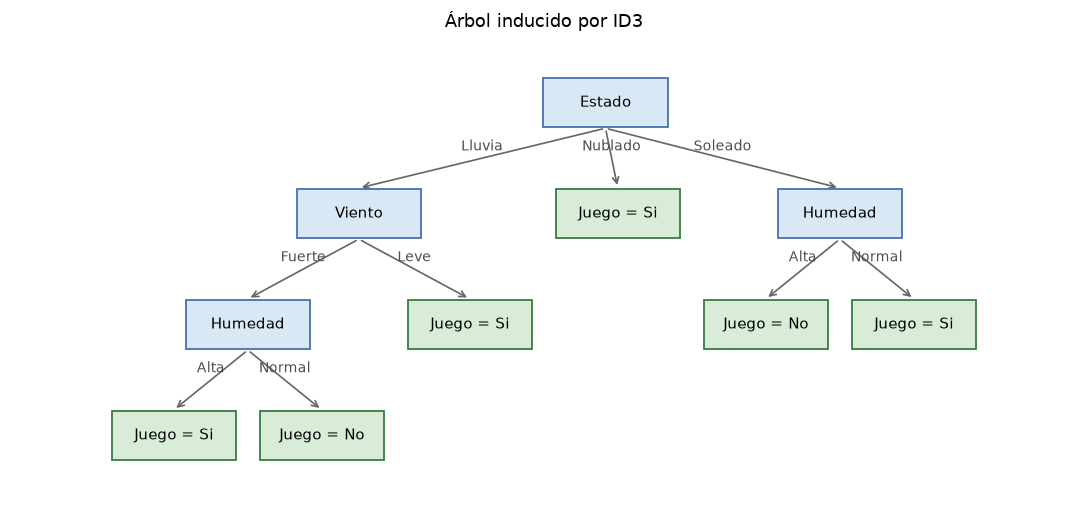

In [9]:
def _n_hojas(nodo):
    if nodo.es_hoja():
        return 1
    return sum(_n_hojas(h) for h in nodo.hijos.values())


def dibujar_arbol(nodo, objetivo, titulo=""):
    """Dibuja el árbol con matplotlib: una unidad de ancho por hoja."""
    fig, ax = plt.subplots(figsize=(12.5, 5.5))
    ax.axis("off")
    cajas, aristas = [], []

    def colocar(n, x0, x1, nivel):
        y = -nivel
        if n.es_hoja():
            xc = (x0 + x1) / 2
            cajas.append((xc, y, f"{objetivo} = {n.valor}", True))
            return xc
        xi = x0
        centros = []
        for valor, hijo in n.hijos.items():
            w = (x1 - x0) * _n_hojas(hijo) / _n_hojas(n)
            centros.append((valor, colocar(hijo, xi, xi + w, nivel + 1)))
            xi += w
        xc = sum(c for _, c in centros) / len(centros)
        cajas.append((xc, y, n.atributo, False))
        for valor, centro in centros:
            aristas.append(((xc, y), (centro, y - 1), valor))
        return xc

    colocar(nodo, 0, _n_hojas(nodo), 0)

    for (x0, y0), (x1, y1), valor in aristas:
        ax.annotate("", xy=(x1, y1 + 0.23), xytext=(x0, y0 - 0.23),
                    arrowprops=dict(arrowstyle="->", color="0.4", lw=1.1))
        ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.07, valor,
                ha="center", fontsize=9, color="0.3")

    for x, y, etiqueta, hoja in cajas:
        ax.add_patch(plt.Rectangle(
            (x - 0.42, y - 0.22), 0.84, 0.44,
            facecolor="#d8ecd8" if hoja else "#d9e8f5",
            edgecolor="#3a7d44" if hoja else "#4c72b0",
            linewidth=1.2, zorder=3))
        ax.text(x, y, etiqueta, ha="center", va="center", fontsize=10, zorder=4)

    ax.set_xlim(-0.6, _n_hojas(nodo) + 0.6)
    ax.set_ylim(min(y for _, y, _, _ in cajas) - 0.6, 0.6)
    if titulo:
        ax.set_title(titulo)
    plt.show()


dibujar_arbol(arbol_id3, OBJETIVO, titulo="Árbol inducido por ID3")

### Reglas de decisión

Cada camino desde la raíz hasta una hoja equivale a una regla SI-ENTONCES: el
antecedente son los tests del camino y el consecuente, la clase de la hoja. El recorrido
siguiente las extrae en orden de profundidad; el árbol y el conjunto de reglas son
modelos equivalentes.

In [10]:
def extraer_reglas(nodo, camino=None, reglas=None):
    """Extrae las reglas IF-THEN equivalentes al árbol, una por hoja."""
    if reglas is None:
        reglas = []
    if camino is None:
        camino = []
    if nodo.es_hoja():
        reglas.append((list(camino), nodo.valor))
        return reglas
    for valor, hijo in nodo.hijos.items():
        extraer_reglas(hijo, camino + [(nodo.atributo, valor)], reglas)
    return reglas


def imprimir_reglas(reglas, objetivo):
    for i, (condiciones, clase) in enumerate(reglas):
        antecedente = " Y ".join(f"{a} = {v}" for a, v in condiciones) or "VERDADERO"
        print(f"R{i + 1}: SI {antecedente} ENTONCES {objetivo} = {clase}")


reglas_id3 = extraer_reglas(arbol_id3)
imprimir_reglas(reglas_id3, OBJETIVO)

R1: SI Estado = Lluvia Y Viento = Fuerte Y Humedad = Alta ENTONCES Juego = Si
R2: SI Estado = Lluvia Y Viento = Fuerte Y Humedad = Normal ENTONCES Juego = No
R3: SI Estado = Lluvia Y Viento = Leve ENTONCES Juego = Si
R4: SI Estado = Nublado ENTONCES Juego = Si
R5: SI Estado = Soleado Y Humedad = Alta ENTONCES Juego = No
R6: SI Estado = Soleado Y Humedad = Normal ENTONCES Juego = Si


## 7. C4.5

C4.5 conserva la estructura recursiva de ID3 y cambia el criterio de selección. El
selector implementado aquí aplica las dos decisiones de Quinlan para elegir el test de
un nodo:

1. Filtro de ganancia: sólo compiten los atributos cuya ganancia alcanza o supera la
   ganancia promedio de los disponibles.
2. Entre esos candidatos, se elige el de mayor gain ratio.

El resto de las extensiones de C4.5 — discretización de atributos continuos, propagación
de ejemplos con valores faltantes, poda pesimista con nivel de confianza y ramas
ponderadas — no se implementan acá por extensión. El selector encapsula el punto de
variación: incorporarlas significa reemplazar o complejar esa función sin tocar la
construcción recursiva.

In [11]:
def selector_c45(df, atributos, objetivo):
    """C4.5: mayor gain ratio entre los atributos con ganancia >= promedio."""
    ganancias = {a: ganancia(df, a, objetivo) for a in atributos}
    umbral = sum(ganancias.values()) / len(ganancias)
    candidatos = [a for a in atributos if ganancias[a] >= umbral] or list(atributos)
    return max(candidatos, key=lambda a: gain_ratio(df, a, objetivo))


arbol_c45 = construir_arbol(df, ATRIBUTOS, OBJETIVO, selector_c45)
describir_arbol(arbol_c45)

print()
reglas_c45 = extraer_reglas(arbol_c45)
imprimir_reglas(reglas_c45, OBJETIVO)

mismas = ([c for c, _ in reglas_id3] == [c for c, _ in reglas_c45]
          and [v for _, v in reglas_id3] == [v for _, v in reglas_c45])
print(f"\n¿Mismas reglas que ID3? {mismas}")

[Estado]  {'No': 4, 'Si': 10}
  (Lluvia)
    [Viento]  {'Si': 4, 'No': 1}
      (Fuerte)
        [Humedad]  {'No': 1, 'Si': 1}
          (Alta)
            -> Juego = Si  {'Si': 1}
          (Normal)
            -> Juego = No  {'No': 1}
      (Leve)
        -> Juego = Si  {'Si': 3}
  (Nublado)
    -> Juego = Si  {'Si': 4}
  (Soleado)
    [Humedad]  {'No': 3, 'Si': 2}
      (Alta)
        -> Juego = No  {'No': 3}
      (Normal)
        -> Juego = Si  {'Si': 2}

R1: SI Estado = Lluvia Y Viento = Fuerte Y Humedad = Alta ENTONCES Juego = Si
R2: SI Estado = Lluvia Y Viento = Fuerte Y Humedad = Normal ENTONCES Juego = No
R3: SI Estado = Lluvia Y Viento = Leve ENTONCES Juego = Si
R4: SI Estado = Nublado ENTONCES Juego = Si
R5: SI Estado = Soleado Y Humedad = Alta ENTONCES Juego = No
R6: SI Estado = Soleado Y Humedad = Normal ENTONCES Juego = Si

¿Mismas reglas que ID3? True


## 8. Evaluación del clasificador

Para un clasificador $C$ sobre $n$ instancias:

$$\mathrm{Exactitud} = \frac{\text{predicciones correctas}}{n} \qquad
\mathrm{Error} = \frac{\text{predicciones incorrectas}}{n} = 1 - \mathrm{Exactitud}$$

La matriz de confusión cruza clase real contra clase predicha y muestra dónde se
concentran los errores. Con clases desbalanceadas conviene mirarla antes que la
exactitud global: un clasificador que siempre responde la clase mayoritaria ya alcanza
el $10/14 = 71.4\,\%$ sin haber aprendido nada.

Se evalúa en dos niveles:

- **Resustitución**: se predice el mismo conjunto con el que se entrenó. El resultado es
  una cota superior sin valor predictivo; sirve para verificar que el árbol memoriza el
  entrenamiento.
- **Leave-one-out**: se inducen $n$ árboles, cada uno dejando una instancia afuera, y se
  predicen las $n$ instancias reales. Con tan pocos datos es la estimación menos sesgada
  que se puede hacer sin salir del dataset.

In [12]:
def predecir_conjunto(nodo, datos):
    return [nodo.predecir(fila) for _, fila in datos.iterrows()]


def matriz_confusion(reales, predichos, clases):
    tabla = pd.crosstab(pd.Series(reales, name="real"), pd.Series(predichos, name="predicho"))
    return tabla.reindex(index=clases, columns=clases, fill_value=0)


reales = df[OBJETIVO].tolist()
predichos = predecir_conjunto(arbol_id3, df)

exactitud = sum(r == p for r, p in zip(reales, predichos)) / len(reales)
print(f"Exactitud (resustitución) = {exactitud:.4f}")
print(f"Error                      = {1 - exactitud:.4f}")

confusion = matriz_confusion(reales, predichos, ["Si", "No"])
confusion

Exactitud (resustitución) = 1.0000
Error                      = 0.0000


predicho,Si,No
real,,
Si,10,0
No,0,4


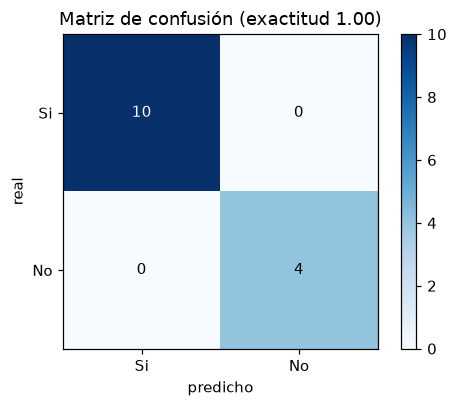

,precision,recall,f1
clase,,,
Si,1.0,1.0,1.0
No,1.0,1.0,1.0


In [13]:
fig, ax = plt.subplots(figsize=(4.8, 3.8))
imagen = ax.imshow(confusion.values, cmap="Blues")
ax.set_xticks(range(len(confusion.columns)), confusion.columns)
ax.set_yticks(range(len(confusion.index)), confusion.index)
ax.set_xlabel("predicho")
ax.set_ylabel("real")
ax.grid(False)
for i in range(confusion.shape[0]):
    for j in range(confusion.shape[1]):
        valor = confusion.values[i, j]
        ax.text(j, i, str(valor), ha="center", va="center",
                color="black" if valor < confusion.values.max() * 0.6 else "white")
ax.set_title(f"Matriz de confusión (exactitud {exactitud:.2f})")
fig.colorbar(imagen, fraction=0.046)
fig.tight_layout()
plt.show()


def metricas_por_clase(confusion):
    """Precisión, recall y F1 por clase a partir de la matriz de confusión."""
    filas = []
    for clase in confusion.columns:
        tp = confusion.loc[clase, clase]
        precision = tp / confusion[clase].sum()
        recall = tp / confusion.loc[clase].sum()
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        filas.append({"clase": clase, "precision": precision, "recall": recall, "f1": f1})
    return pd.DataFrame(filas).set_index("clase")


metricas_por_clase(confusion).round(4)

In [14]:
aciertos_loo = 0
for i in range(len(df)):
    entrenamiento = df.drop(df.index[i])
    instancia = df.iloc[i]
    arbol_parcial = construir_arbol(entrenamiento, ATRIBUTOS, OBJETIVO, selector_id3)
    if arbol_parcial.predecir(instancia) == instancia[OBJETIVO]:
        aciertos_loo += 1

exactitud_loo = aciertos_loo / len(df)
print(f"Exactitud leave-one-out = {aciertos_loo}/{len(df)} = {exactitud_loo:.4f}")

Exactitud leave-one-out = 12/14 = 0.8571


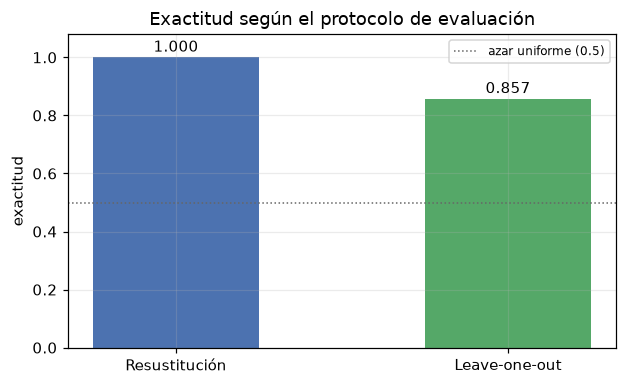

In [15]:
fig, ax = plt.subplots(figsize=(5.8, 3.6))
valores = [exactitud, exactitud_loo]
ax.bar(["Resustitución", "Leave-one-out"], valores,
       color=["#4c72b0", "#55a868"], width=0.5)
ax.axhline(0.5, color="0.4", ls=":", lw=1, label="azar uniforme (0.5)")
ax.set_ylim(0, 1.08)
ax.set_ylabel("exactitud")
ax.set_title("Exactitud según el protocolo de evaluación")
ax.legend(fontsize=8)
for x, v in enumerate(valores):
    ax.text(x, v + 0.02, f"{v:.3f}", ha="center")
fig.tight_layout()
plt.show()

## 9. Conclusiones

- El dataset tiene entropía 0.8631 bits: sin información sobre las condiciones, decidir
  si se juega es casi una moneda sesgada.
- `Estado` concentra la mayor parte de la información disponible. Es nodo raíz por
  ganancia y por gain ratio, y sus ramas `Nublado` (pura) y `Soleado` (casi pura)
  resuelven 9 de las 14 instancias con un solo test.
- ID3 y C4.5 producen el mismo árbol sobre este dataset: los tres atributos tienen pocos
  valores y la ventaja del gain ratio no llega a expresarse. La diferencia se ve en
  conjuntos con atributos de alta cardinalidad.
- El modelo equivale a 6 reglas SI-ENTONCES, extraídas con un recorrido de profundidad.
- La brecha entre la exactitud de resustitución (1.0) y la leave-one-out (0.857) mide el
  sobreajuste: con 14 instancias el árbol memoriza particularidades del entrenamiento.
  En un caso real se agregaría poda (pesimista en C4.5, *cost-complexity* en CART) y
  validación estratificada sobre muchos más datos.

Extensiones naturales de este cuaderno: discretización de atributos continuos,
tratamiento de valores faltantes, poda y comparación contra un modelo lineal o un
ensemble usando el mismo pliego de evaluación.